In [43]:
'''
This file calculates the pearson correlation between the top N features
'''
import pickle
import pandas as pd
import seaborn as sb
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr
from scipy.spatial.distance import squareform
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram

PCC = 0.8                   # Pearson Correlation Coefficient
IMPORTANCE_FLOOR = 0.90
MAX_ITERATIONS = 30         # max iterations for cluster and filter


In [44]:
def load_data(fold_num):
    return pd.read_csv(f"bcg_dataset/feat_fold_{fold_num}.csv")

def load_all_data():
    """
    Load and combine all pre-split folds into one dataset
    
    The original dataset comes pre-split into 5 folds, but I combine them so I can split using
    groups over the patient id
    """
    all_folds = []
    for fold_num in range(5):
        fold_data = load_data(fold_num)
        all_folds.append(fold_data)
    
    combined = pd.concat(all_folds, ignore_index=True)
    print(f"Combined dataset shape: {combined.shape}")
    print(f"Total samples: {len(combined)}")
    
    return combined

In [45]:
def cluster_and_filter(top_features, data, pcc=0.8):
    '''
    This function calculates the corr matrix, then turns it into a distance matrix of the corr values and then clusters them into clusters using labels based on their distances
    '''
    feature_names = [f for f,_ in top_features]
    importances = {f: imp for f, imp in top_features}
    X = data[feature_names]
    
    corr_absolute = X.corr(method="pearson").abs()
    dist_matrix = 1.0 - corr_absolute.values
    np.fill_diagonal(dist_matrix,0.0)
    dist_matrix = np.clip(dist_matrix, 0.0, None)
    condensed = squareform(dist_matrix, checks=False) # get an array of size N*(N-1)/2, i.e. all the values without the symmetric second half triangle values and the diagonal values (always 0s)

    Z = linkage(condensed, method="average")
    labels = fcluster(Z,t=(1.0- pcc), criterion="distance")     # any features with a distance smaller than 1-pcc, will receive the same cluster label

    clusters: dict = {}
    for feat, label in zip(feature_names, labels):
        clusters.setdefault(int(label), []).append(feat)

    kept = []
    dropped = set()
    for label, features in clusters.items():
        best = max(features, key = lambda f: importances[f])
        kept.append((best, importances[best]))
        dropped.update(f for f in features if f != best)
    
    kept.sort(key = lambda x : -x[1])
    return kept, clusters, dropped


def iterative_cluster_filter(top_features, data, pcc=0.8, max_iter=30):
    current = top_features
    for i in range(0,max_iter):
        kept, clusters, dropped = cluster_and_filter(current, data, pcc)
        print(f"Iteration {i}: {len(current)} --> {len(kept)} features\n dropped features: {len(dropped)}")
        if len(kept) == len(current):
            print(f"converged after {i} iterations")
            break
        current = kept
    return kept, clusters, dropped


def spearman_rerank_and_filter(features, data, bp_values, n_bins=5, monotonicity_threshold=0.7):
    """
    Re-ranks features by |Spearman r| with BP and drops non-monotonic ones.
    monotonicity_threshold: minimum |Spearman r| to keep a feature
    """
    bp_series = pd.Series(bp_values, index=data.index)
    bp_bins = pd.qcut(bp_series, q=n_bins, labels=False, duplicates='drop')

    scored = []
    for feat, imp in features:
        r_spearman, _ = spearmanr(data[feat].values, bp_values)

        # monotonicity check: correlation of bin means with bin order
        bin_means = [data.loc[bp_bins == b, feat].mean() for b in range(n_bins)]
        bin_order = list(range(n_bins))
        r_mono, _ = spearmanr(bin_order, bin_means)

        scored.append((feat, imp, r_spearman, r_mono))
        print(f"{feat:<35} spearman_r={r_spearman:>7.3f}  monotonicity={r_mono:>7.3f}  {'KEEP' if abs(r_mono) >= monotonicity_threshold else 'DROP'}")

    kept = [(f, imp) for (f, imp, r_s, r_mono) in scored if abs(r_mono) >= monotonicity_threshold]
    kept.sort(key=lambda x: -abs(dict((f, r_s) for f, _, r_s, _ in scored)[x[0]]))
    return kept


In [46]:
with open("results_RF_importances/rf_results.pkl", "rb") as file:
    results = pickle.load(file)

SBP_features = [(f,imp) for (f, imp) in results["sbp_ranking"][:218]]
DBP_features = [(f,imp) for (f, imp) in results["dbp_ranking"][:218]]
print(SBP_features[0][0])

sumImpSBP = 0
sumImpDBP = 0
num_features_SBP = 0     # represents the top n features to get the summed importance of IMPORTANCE_FLOOR
num_features_DBP = 0

for i in range (len(SBP_features)):
    sumImpSBP += SBP_features[i][1]
    num_features_SBP += 1
    if sumImpSBP>=IMPORTANCE_FLOOR:
        break

for i in range (len(DBP_features)):
    sumImpDBP += DBP_features[i][1]
    num_features_DBP += 1
    if sumImpDBP>=IMPORTANCE_FLOOR:
        break

print(f"Top SBP {num_features_SBP} features with a cumulative importance of {sumImpSBP}")
for i, (f, imp) in enumerate(SBP_features[:num_features_SBP], 1):
    print(f"{i:>3} {f:<40} {imp:.6f}")

print(f"\n\nTop SBP {num_features_DBP} features with a cumulative importance of {sumImpDBP}")
for i, (f, imp) in enumerate(DBP_features[:num_features_DBP], 1):
    print(f"{i:>3} {f:<40} {imp:.6f}")

top_N_features = max(num_features_SBP, num_features_DBP)

# Keep tuples with importance
top_features_SBP = results["sbp_ranking"][:top_N_features]
top_features_DBP = results["dbp_ranking"][:top_N_features]

# Only feature names
top_feature_names_SBP = [f for f, _ in top_features_SBP]
top_feature_names_DBP = [f for f, _ in top_features_DBP]

AUCsys_norm
Top SBP 105 features with a cumulative importance of 0.9001423629387985
  1 AUCsys_norm                              0.125667
  2 TdiaToEnd                                0.116956
  3 AUCdia_norm                              0.062830
  4 T_peak_e_norm                            0.050434
  5 ppg_histogram_down_2                     0.026807
  6 T_peak_a                                 0.025653
  7 SteepDiaRise                             0.021742
  8 TNegSteepest_norm                        0.019118
  9 vpg_max_neighbor_mean_0                  0.017178
 10 ppg4_max_0                               0.015860
 11 TSystoDiaRise                            0.014518
 12 ppg3_histogram_down_8                    0.013950
 13 usdc_2                                   0.011176
 14 T_peak_e                                 0.009860
 15 vpg_histogram_down_0                     0.009217
 16 apg_histogram_down_3                     0.008568
 17 TNegSteepest                             0.00830

Combined dataset shape: (3063, 222)
Total samples: 3063


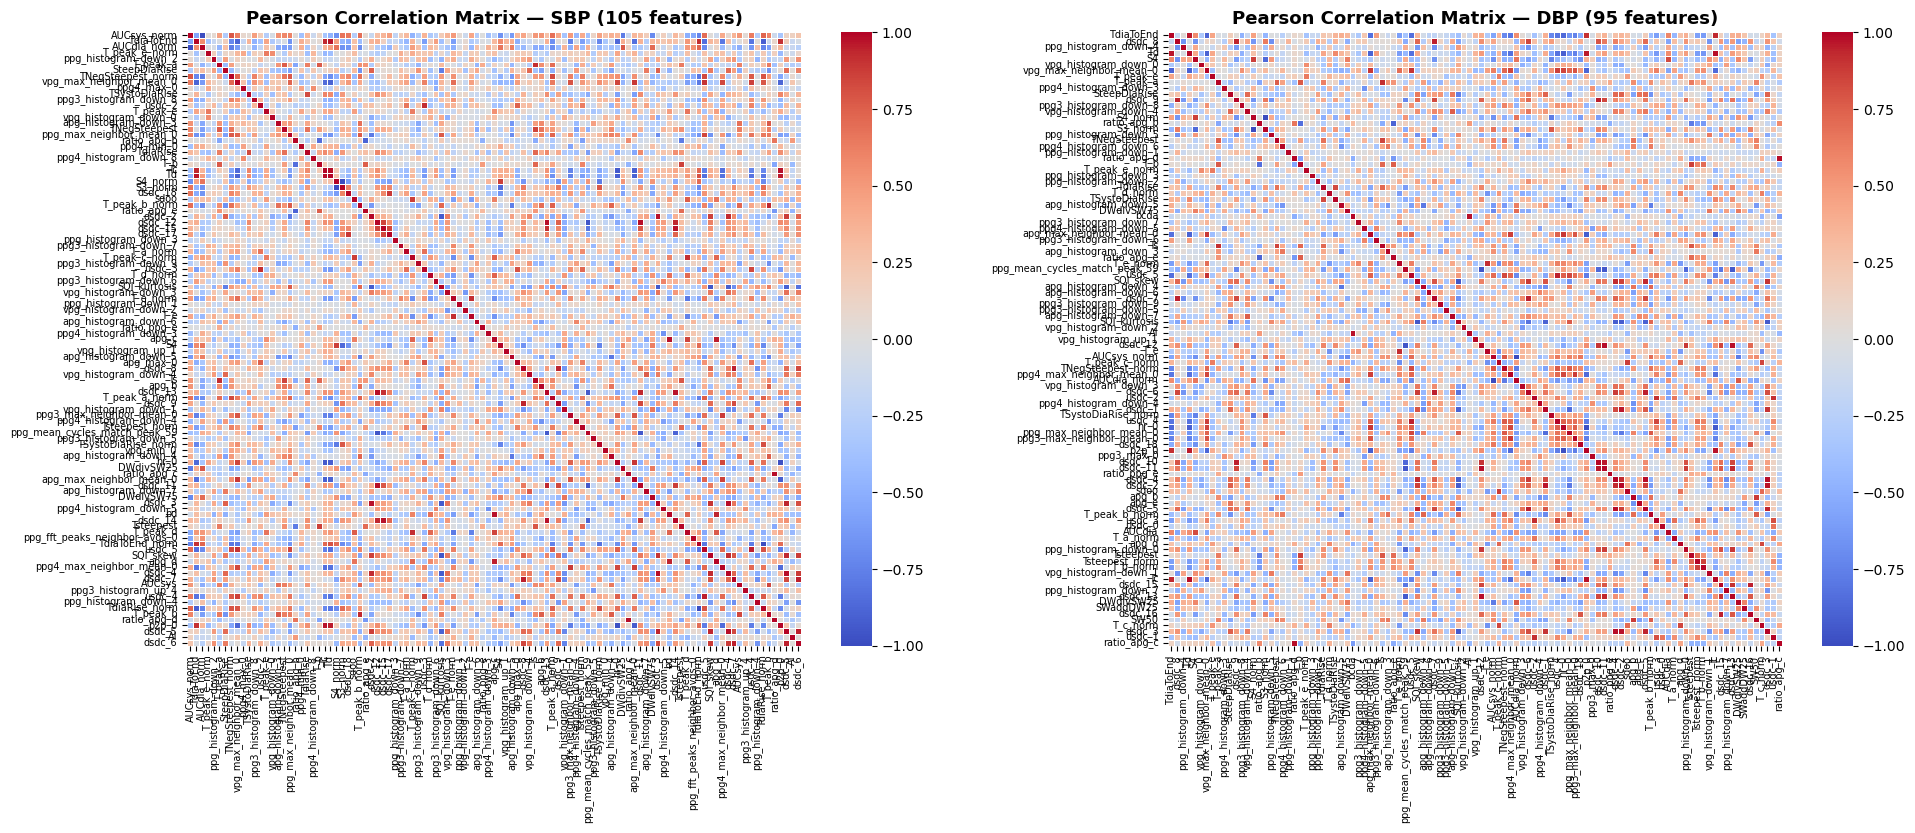

In [47]:
'''
Represent feature correlation matrix prior to iterative filtering and clustering
'''
data = load_all_data()

X_SBP = data[top_feature_names_SBP]
X_DBP = data[top_feature_names_DBP]

corr_SBP = X_SBP.corr(method="pearson")
corr_DBP = X_DBP.corr(method="pearson")

# Plot
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

sb.heatmap(
    corr_SBP,
    ax=axes[0],
    cmap='coolwarm',
    center=0,
    vmin=-1, vmax=1,
    square=True,
    linewidths=0.5,
    annot=False,
    xticklabels=True,
    yticklabels=True
)
axes[0].set_title(f'Pearson Correlation Matrix — SBP ({num_features_SBP} features)', fontsize=13, fontweight='bold')
axes[0].tick_params(axis='x', rotation=90, labelsize=7)
axes[0].tick_params(axis='y', rotation=0,  labelsize=7)

sb.heatmap(
    corr_DBP,
    ax=axes[1],
    cmap='coolwarm',
    center=0,
    vmin=-1, vmax=1,
    square=True,
    linewidths=0.5,
    annot=False,
    xticklabels=True,
    yticklabels=True
)
axes[1].set_title(f'Pearson Correlation Matrix — DBP ({num_features_DBP} features)', fontsize=13, fontweight='bold')
axes[1].tick_params(axis='x', rotation=90, labelsize=7)
axes[1].tick_params(axis='y', rotation=0,  labelsize=7)

plt.tight_layout()
plt.savefig('results_RF_importances/pearson_correlation_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

iterative clustering for SBP using PPC: 0.8
Iteration 0: 105 --> 63 features
 dropped features: 42
Iteration 1: 63 --> 62 features
 dropped features: 1
Iteration 2: 62 --> 62 features
 dropped features: 0
converged after 2 iterations
iterative clustering for DBP using PPC: 0.8
Iteration 0: 105 --> 64 features
 dropped features: 41
Iteration 1: 64 --> 60 features
 dropped features: 4
Iteration 2: 60 --> 60 features
 dropped features: 0
converged after 2 iterations
AUCsys_norm                         spearman_r=  0.213  monotonicity=  0.100  DROP
TdiaToEnd                           spearman_r= -0.026  monotonicity=  0.000  DROP
T_peak_e_norm                       spearman_r= -0.314  monotonicity= -1.000  KEEP
ppg_histogram_down_2                spearman_r= -0.300  monotonicity= -0.600  DROP
T_peak_a                            spearman_r=  0.242  monotonicity=  0.300  DROP
SteepDiaRise                        spearman_r= -0.224  monotonicity= -0.400  DROP
TNegSteepest_norm                 

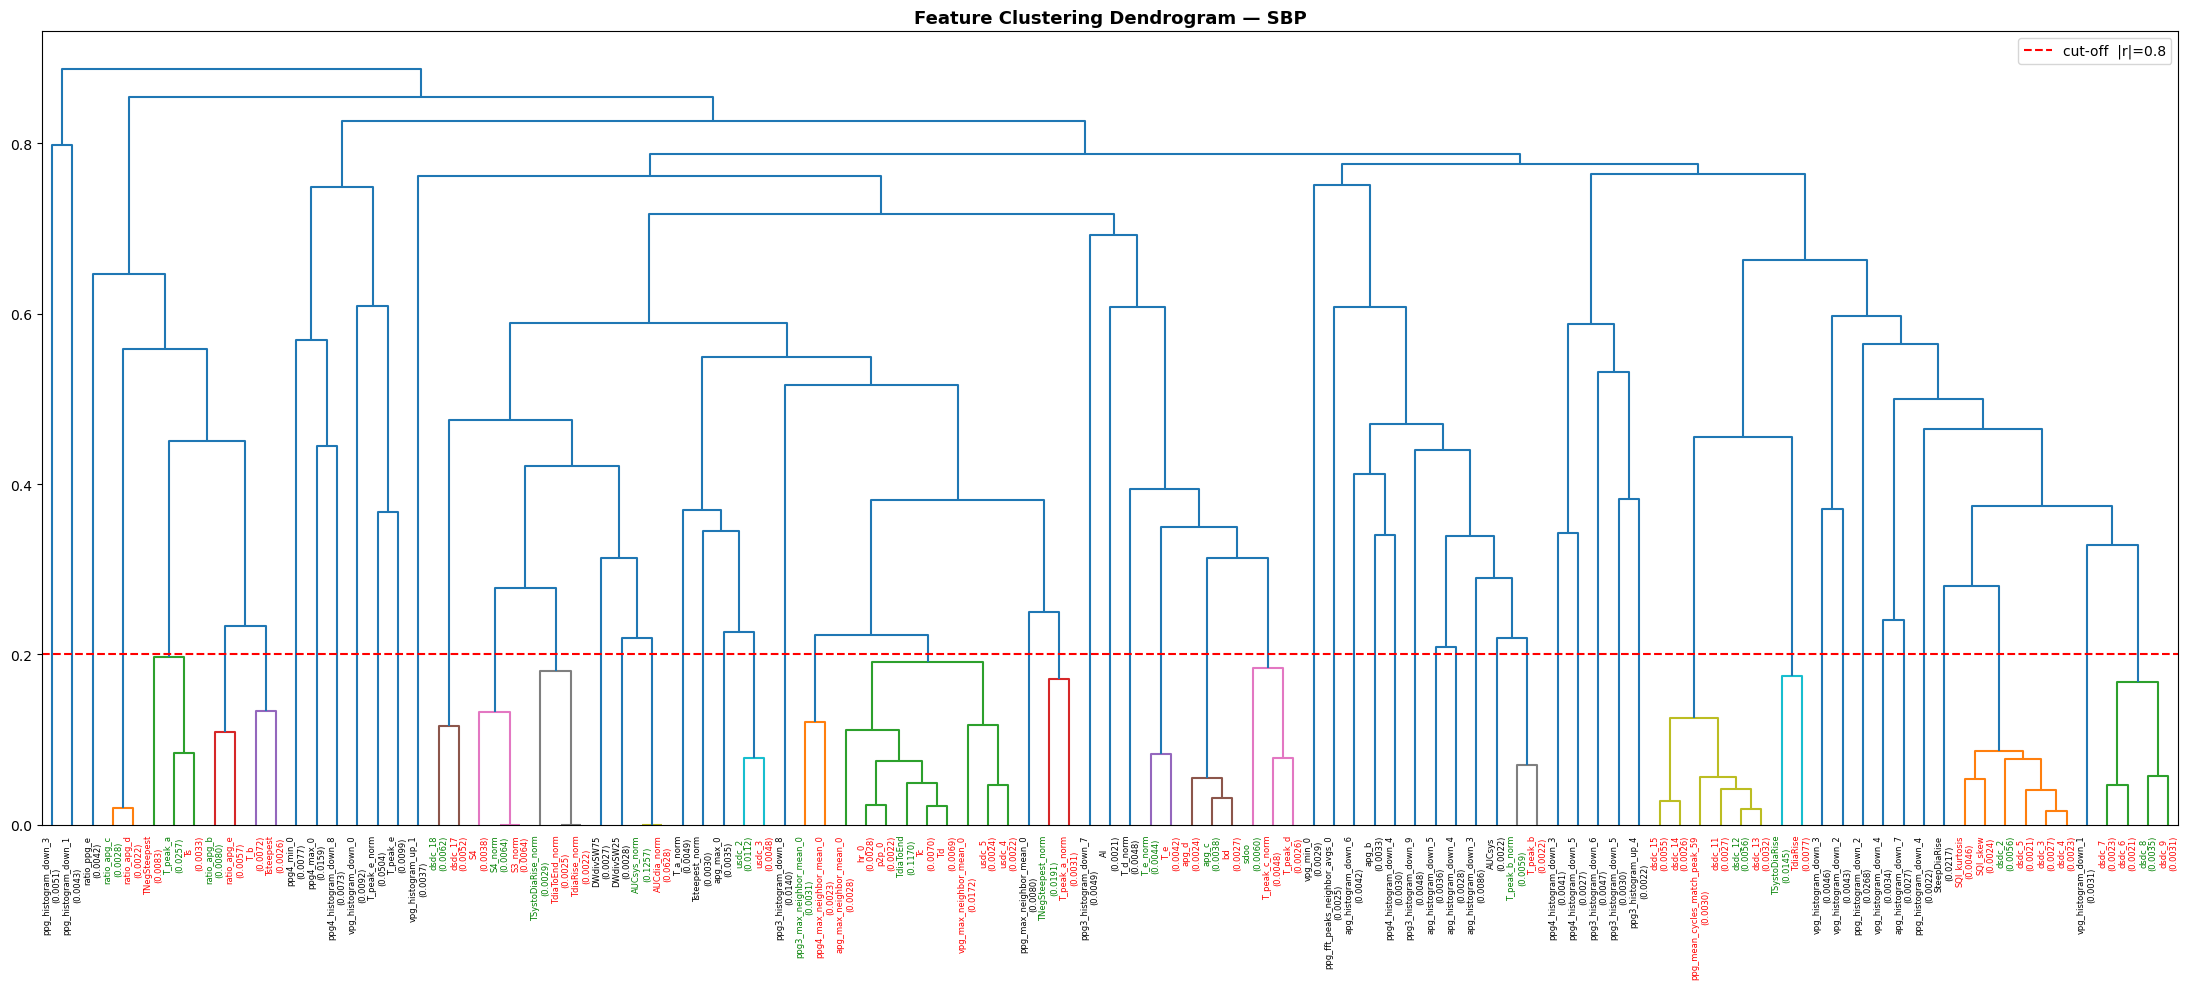

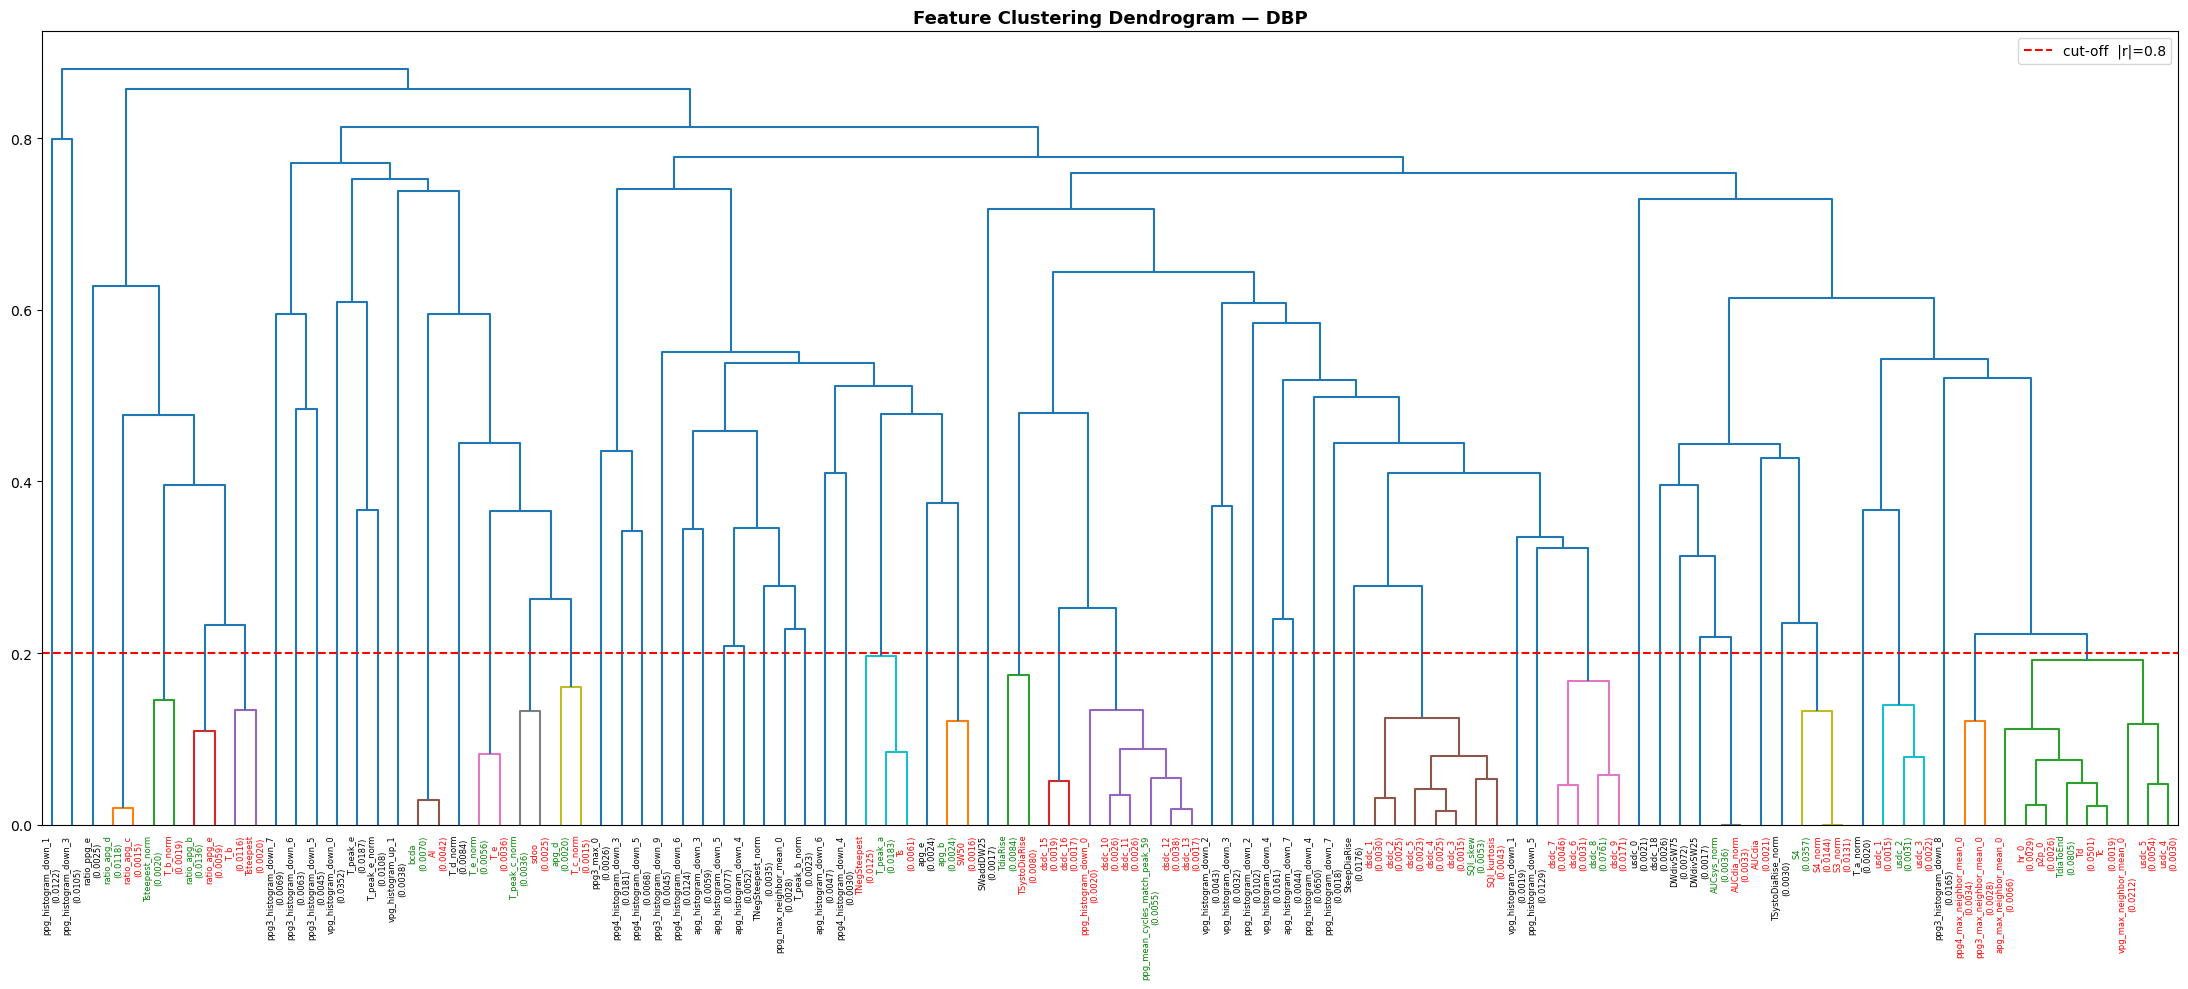


SBP — contested clusters (PCC=0.8)

  Cluster 1:
    KEPT        AUCsys_norm                     0.125667
    dropped     AUCdia_norm                     0.062830

  Cluster 2:
    KEPT        TdiaToEnd                       0.116956
    dropped     vpg_max_neighbor_mean_0         0.017178
    dropped     Tc                              0.006965
    dropped     Td                              0.006948
    dropped     hr_0                            0.002832
    dropped     apg_max_neighbor_mean_0         0.002757
    dropped     usdc_5                          0.002438
    dropped     usdc_4                          0.002197
    dropped     p2p_0                           0.002156

  Cluster 3:
    KEPT        T_peak_a                        0.025653
    dropped     TNegSteepest                    0.008305
    dropped     Ts                              0.003300

  Cluster 4:
    KEPT        TNegSteepest_norm               0.019118
    dropped     T_peak_a_norm                   0.003

In [48]:
print(f"iterative clustering for SBP using PPC: {PCC}")
filtered_SBP, clusters_SBP, dropped_SBP = iterative_cluster_filter(top_features_SBP, data, PCC, MAX_ITERATIONS)

print(f"iterative clustering for DBP using PPC: {PCC}")
filtered_DBP, clusters_DBP, dropped_DBP = iterative_cluster_filter(top_features_DBP, data, PCC, MAX_ITERATIONS)

sbp_values = data.iloc[:, 2].values
dbp_values = data.iloc[:, 3].values

filtered_SBP_spearman = spearman_rerank_and_filter(filtered_SBP, data, sbp_values)
filtered_DBP_spearman = spearman_rerank_and_filter(filtered_DBP, data, dbp_values)

kept_SBP = set(f for f, _ in filtered_SBP)
kept_DBP = set(f for f, _ in filtered_DBP)

all_dropped_SBP = set(f for f, _ in top_features_SBP) - kept_SBP
all_dropped_DBP = set(f for f, _ in top_features_DBP) - kept_DBP

print(f"SBP: {len(top_features_SBP)} --> {len(filtered_SBP)} features kept")
print(f"    Kept: {[f for f, _ in filtered_SBP]}")
print(f"    Dropped: {all_dropped_SBP}")

print(f"\nDBP: {len(top_features_DBP)} --> {len(filtered_DBP)} features kept")
print(f"    Kept: {[f for f, _ in filtered_DBP]}")
print(f"    Dropped: {all_dropped_DBP}")


# plot dendrogram 
for feats, label, all_dropped in [
    (top_features_SBP, "SBP", all_dropped_SBP),
    (top_features_DBP, "DBP", all_dropped_DBP),
]:
    names       = [f for f, _ in feats]
    importances = {f: imp for f, imp in feats}
    X           = data[names]
    dist        = squareform(
        np.clip(1.0 - X.corr(method="pearson").abs().values, 0, None),
        checks=False
    )
    Z = linkage(dist, method="average")

    _, orig_clusters, _ = cluster_and_filter(feats, data, PCC)
    contested_kept = set()
    for cluster_feats in orig_clusters.values():
        if len(cluster_feats) > 1:
            for f in cluster_feats:
                if f not in all_dropped:
                    contested_kept.add(f)

    fig, ax = plt.subplots(figsize=(22, 10))

    dendrogram(Z, labels=names, ax=ax, leaf_rotation=90, leaf_font_size=6,
               color_threshold=(1.0 - PCC))

    new_labels = []
    for tick in ax.get_xticklabels():
        fname = tick.get_text()
        imp   = importances.get(fname, 0.0)
        tick.set_text(f"{fname}\n({imp:.4f})")
        if fname in all_dropped:
            tick.set_color("red")
        elif fname in contested_kept:
            tick.set_color("green")
        # singletons stay default black
        new_labels.append(tick)
    ax.set_xticklabels(new_labels, fontsize=6)

    ax.axhline(y=(1.0 - PCC), color="red", linestyle="--",
               label=f"cut-off  |r|={PCC}")
    ax.set_title(f"Feature Clustering Dendrogram — {label}",
                 fontsize=13, fontweight="bold")
    ax.legend()

    plt.tight_layout()
    plt.savefig(f"results_RF_importances/clustering_dendrogram_{label}.png", dpi=300, bbox_inches="tight")
    plt.show()


# PRINT: clusters with competition
for feats, label, all_dropped in [
    (top_features_SBP, "SBP", all_dropped_SBP),
    (top_features_DBP, "DBP", all_dropped_DBP),
]:
    _, orig_clusters, _ = cluster_and_filter(feats, data, PCC)
    importances = {f: imp for f, imp in feats}

    print(f"\n{'='*60}")
    print(f"{label} — contested clusters (PCC={PCC})")
    print(f"{'='*60}")

    contested = {k: v for k, v in orig_clusters.items() if len(v) > 1}
    for i, (cluster_id, cluster_feats) in enumerate(contested.items(), 1):
        sorted_feats = sorted(cluster_feats, key=lambda f: importances[f], reverse=True)
        winner = sorted_feats[0]
        print(f"\n  Cluster {i}:")
        for f in sorted_feats:
            tag = "KEPT" if f == winner else "dropped"
            print(f"    {tag:<10}  {f:<30}  {importances[f]:.6f}")


with open("results_RF_importances/rf_results.pkl", "rb") as f:
    file = pickle.load(f)

file.update({
    "sbp_ranking_pearson": filtered_SBP,
    "dbp_ranking_pearson": filtered_DBP,
    "sbp_ranking_spearman": filtered_SBP_spearman,
    "dbp_ranking_spearman": filtered_DBP_spearman
})
print([f for f,_ in filtered_SBP])
print([f for f,_ in filtered_DBP])

with open("results_RF_importances/rf_results.pkl", "wb") as f:
    pickle.dump(file, f)
    